# WeVisOne-VL: OCR in two modes

Run the same image through both OCR interfaces: **end-to-end OCR** detects and transcribes every visible word, while **OCR grounding** locates only the requested text.

## 1. Load the released model

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

from wevisone_vl import WeVisOneVL
from wevisone_vl.visualization import render_overlay, save_result


def find_repo_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "wevisone_vl").is_dir() and (candidate / "demo").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from inside the WeVisOne-VL repository.")


repo_root = find_repo_root()
examples_dir = repo_root / "demo" / "examples"
local_checkpoint = repo_root / "checkpoints" / "WeVisOne-VL-4B"
model_path = os.environ.get("WEVISONE_MODEL") or (
    str(local_checkpoint) if local_checkpoint.is_dir() else "tencent/WeVisOne-VL-4B"
)
print(f"Loading WeVisOne-VL from: {model_path}")

model = WeVisOneVL(
    model_path,
    backend="transformers",
    device="auto",
    dtype="bfloat16",
)

Loading WeVisOne-VL from: checkpoints/WeVisOne-VL-4B


## 2. Load one shared image

Image: demo/examples/images/coffee_sign.jpg | size=(424, 640)


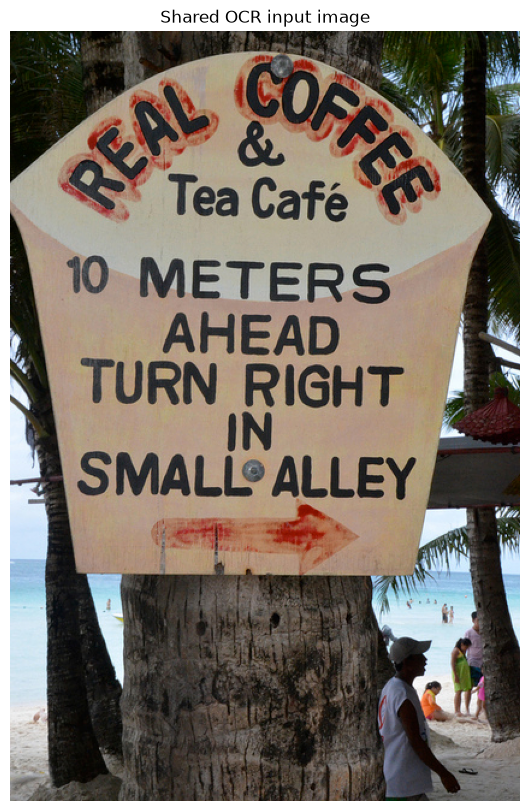

In [2]:
image_path = examples_dir / "images" / "coffee_sign.jpg"
image = Image.open(image_path).convert("RGB")
output_root = repo_root / "outputs" / "ocr_pipeline"
print(f"Image: {image_path} | size={image.size}")

plt.figure(figsize=(7, 10))
plt.imshow(image)
plt.axis("off")
plt.title("Shared OCR input image")
plt.show()

## 3. End-to-end OCR

Detect and recognize all words without supplying a text query.

Prompt: detect all the word in the box format
Raw response: <ref>COFFEE</ref><box><450><33><850><250></box>, <ref>REAL</ref><box><94><62><406><245></box>, <ref>&</ref><box><443><116><540><179></box>, <ref>Tea</ref><box><308><184><452><242></box>, <ref>Café</ref><box><470><187><666><252></box>, <ref>10</ref><box><107><289><193><342></box>, <ref>METERS</ref><box><251><291><751><357></box>, <ref>AHEAD</ref><box><296><363><647><423></box>, <ref>TURN</ref><box><135><422><410><487></box>, <ref>RIGHT</ref><box><457><429><775><491></box>, <ref>IN</ref><box><424><492><515><547></box>, <ref>SMALL</ref><box><129><544><480><606></box>, <ref>ALLEY</ref><box><512><548><799><609></box>
Latency: 9.52s
Saved overlay: outputs/ocr_pipeline/01_end_to_end_ocr/overlay.png


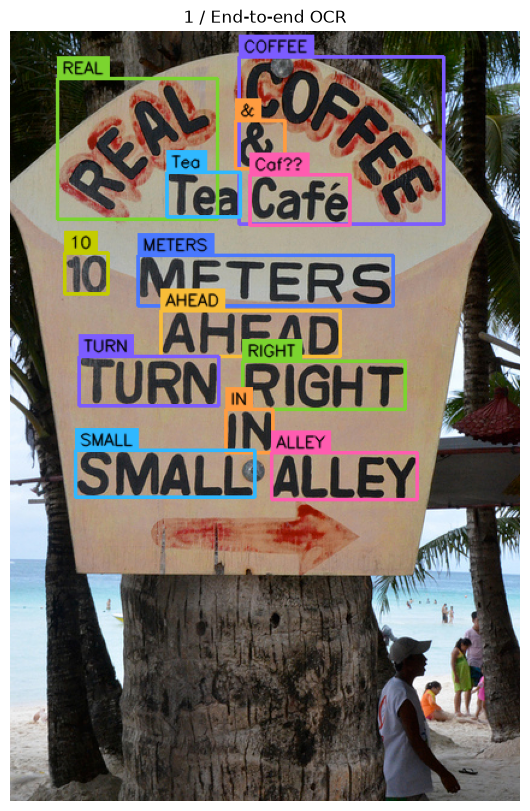

In [3]:
ocr_result = model.predict(
    image,
    task="ocr",
    max_new_tokens=4096,
    temperature=0.0,
)
ocr_paths = save_result(output_root / "01_end_to_end_ocr", image, ocr_result)
ocr_visualization = render_overlay(image, ocr_result)

print("Prompt:", ocr_result.prompt)
print("Raw response:", ocr_result.response)
print(f"Latency: {ocr_result.latency_s:.2f}s")
print("Saved overlay:", ocr_paths["overlay"])
plt.figure(figsize=(7, 10))
plt.imshow(ocr_visualization)
plt.axis("off")
plt.title("1 / End-to-end OCR")
plt.show()

## 4. OCR grounding

Locate the phrase `SMALL ALLEY` and ignore the other text.

Prompt: Locate the following text in the image: SMALL ALLEY
Raw response: <ref>SMALL ALLEY</ref><box><122><536><804><614></box>
Latency: 0.43s
Saved overlay: outputs/ocr_pipeline/02_ocr_grounding/overlay.png


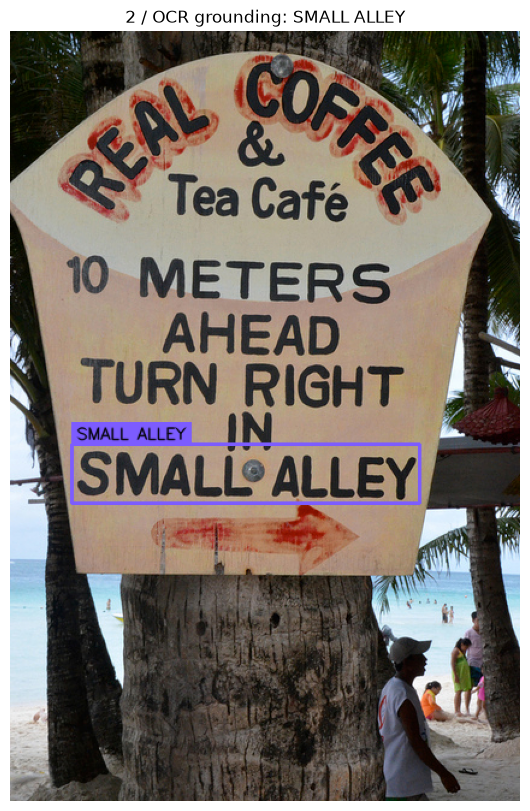

In [4]:
ocr_grounding_result = model.predict(
    image,
    task="ocr_grounding",
    query="SMALL ALLEY",
    max_new_tokens=4096,
    temperature=0.0,
)
ocr_grounding_paths = save_result(
    output_root / "02_ocr_grounding", image, ocr_grounding_result
)
ocr_grounding_visualization = render_overlay(image, ocr_grounding_result)

print("Prompt:", ocr_grounding_result.prompt)
print("Raw response:", ocr_grounding_result.response)
print(f"Latency: {ocr_grounding_result.latency_s:.2f}s")
print("Saved overlay:", ocr_grounding_paths["overlay"])
plt.figure(figsize=(7, 10))
plt.imshow(ocr_grounding_visualization)
plt.axis("off")
plt.title("2 / OCR grounding: SMALL ALLEY")
plt.show()